# Notebook 05 — Credit Card Analysis

## Objective
To analyse credit card categories, credit limits, transaction amounts, annual fees, revolving balances, and interest earned.

In [11]:
# Import pandas to load and analyse data
import pandas as pd

# Import matplotlib and seaborn to create charts
import matplotlib.pyplot as plt
import seaborn as sns

# Set the chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [12]:
# Load the original credit card dataset
credit_card = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Data Set\credit_card.csv"
)

# Load the additional credit card dataset
cc_add = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Data Set\cc_add.csv"
)

# Display the number of rows and columns
print("Original dataset:", credit_card.shape)
print("Additional dataset:", cc_add.shape)

Original dataset: (10108, 18)
Additional dataset: (185, 19)


In [13]:
# Load the original credit card dataset
credit_card = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Data Set\credit_card.csv"
)

# Load the additional credit card dataset
cc_add = pd.read_csv(
    r"C:\Users\M.SANTHOSH\Downloads\Data Set\cc_add.csv"
)

# Display the number of rows and columns
print("Original dataset:", credit_card.shape)
print("Additional dataset:", cc_add.shape)

Original dataset: (10108, 18)
Additional dataset: (185, 19)


In [14]:
# Remove columns that contain no data at all
cc_add = cc_add.dropna(axis=1, how="all").copy()

# Display the cleaned dataset size
print("Additional dataset after cleaning:", cc_add.shape)

Additional dataset after cleaning: (185, 18)


In [15]:
# Display column names from both datasets
print("Original columns:")
print(credit_card.columns.tolist())

print("\nAdditional columns:")
print(cc_add.columns.tolist())

# Check whether the column names match exactly
print("\nDo column names match?",
      credit_card.columns.tolist() == cc_add.columns.tolist())

Original columns:
['Client_Num', 'Card_Category', 'Annual_Fees', 'Activation_30_Days', 'Customer_Acq_Cost', 'Week_Start_Date', 'Week_Num', 'Qtr', 'current_year', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Trans_Amt', 'Total_Trans_Vol', 'Avg_Utilization_Ratio', 'Use Chip', 'Exp Type', 'Interest_Earned', 'Delinquent_Acc']

Additional columns:
['Client_Num', 'Card_Category', 'Annual_Fees', 'Activation_30_Days', 'Customer_Acq_Cost', 'Week_Start_Date', 'Week_Num', 'Qtr', 'current_year', 'Credit_Limit', 'Total_Revolving_Bal', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Avg_Utilization_Ratio', 'Use Chip', 'Exp Type', 'Interest_Earned', 'Delinquent_Acc']

Do column names match? False


In [16]:
# Combine the original and additional credit card records
credit_cards = pd.concat(
    [credit_card, cc_add],
    ignore_index=True
)

# Display the final dataset size
print("Total credit card records:", credit_cards.shape)

Total credit card records: (10293, 19)


## Credit Card Analysis — Question 1 of 10

###  What is the distribution of customers across credit card categories?

**Why are we running this code?**

To identify the number of records in each credit card category and understand which categories are most common in the dataset.

Card_Category
Blue        9384
Silver       649
Gold         193
Platinum      67
Name: count, dtype: int64


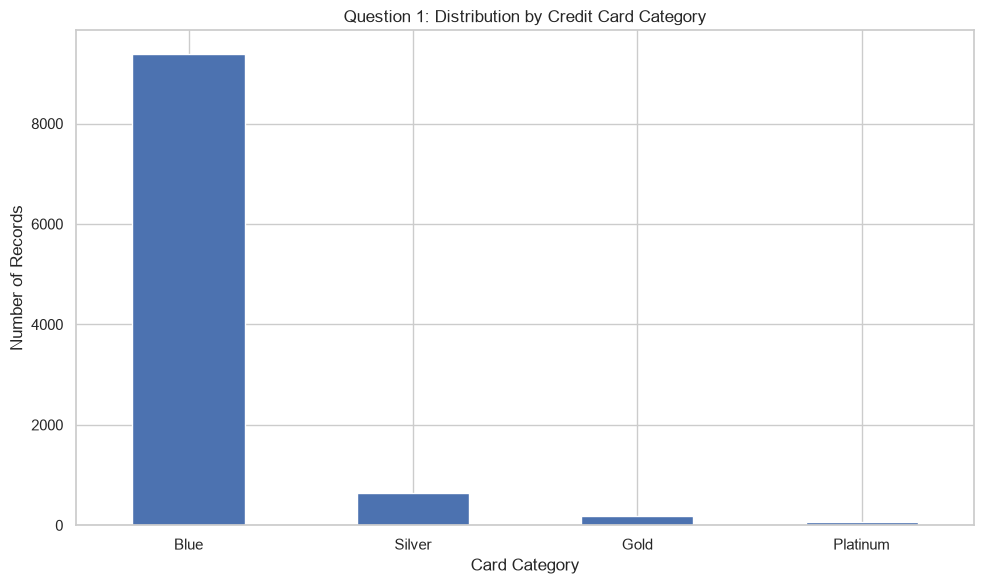

In [17]:
# Count records in each credit card category
card_category_counts = credit_cards["Card_Category"].value_counts()

# Display the counts
print(card_category_counts)

# Create a bar chart
card_category_counts.plot(kind="bar", rot=0)
plt.title("Question 1: Distribution by Credit Card Category")
plt.xlabel("Card Category")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Question 2: What is the total transaction amount for each credit card category?

**Why are we running this code?**

To compare the total transaction amount across credit card categories and identify which category accounts for the highest transaction value.

Card_Category
Blue        37840749
Silver       4647596
Gold         2091362
Platinum      953314
Name: Total_Trans_Amt, dtype: int64


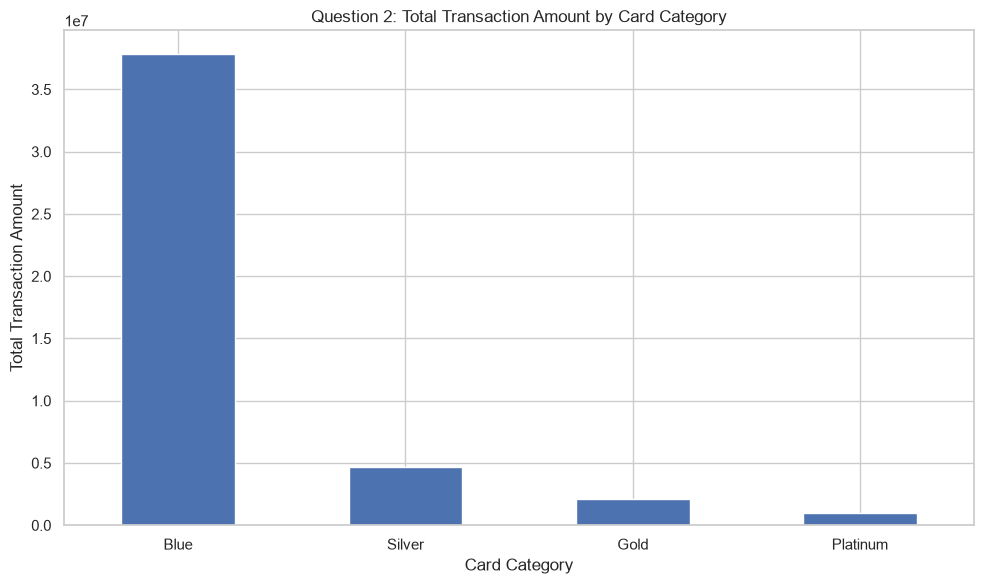

In [19]:
# Calculate the total transaction amount for each card category
transaction_by_category = credit_cards.groupby(
    "Card_Category"
)["Total_Trans_Amt"].sum().sort_values(ascending=False)

# Display the results
print(transaction_by_category)

# Create a bar chart
transaction_by_category.plot(kind="bar", rot=0)
plt.title("Question 2: Total Transaction Amount by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Total Transaction Amount")
plt.tight_layout()
plt.show()

### Question 3: What is the average credit limit for each credit card category?

**Why are we running this code?**

To compare average credit limits across card categories and understand how credit limits differ between categories.

Card_Category
Silver      23454.970724
Gold        21792.668394
Platinum    16455.134328
Blue         7291.732843
Name: Credit_Limit, dtype: float64


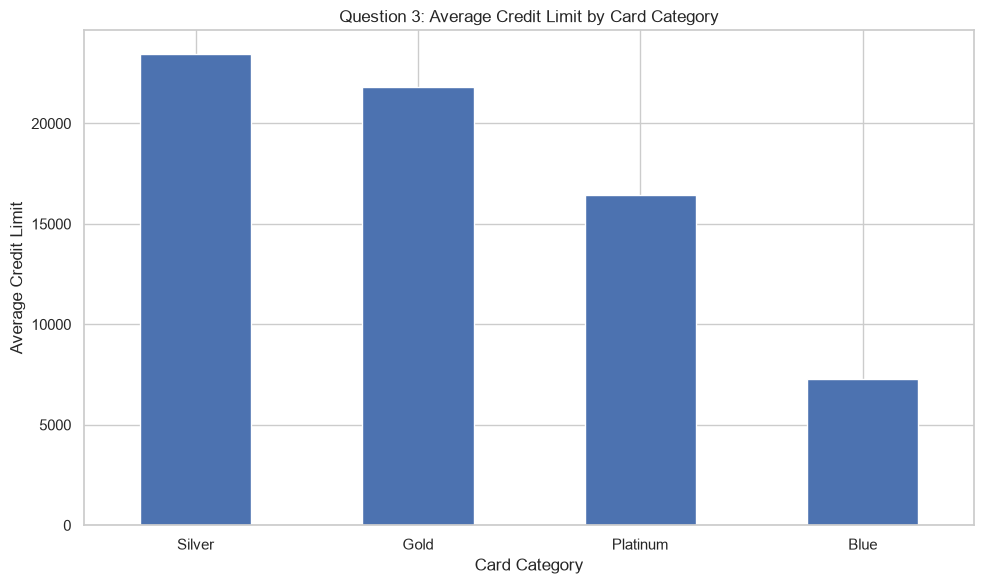

In [21]:
# Calculate the average credit limit for each card category
average_limit = credit_cards.groupby(
    "Card_Category"
)["Credit_Limit"].mean().sort_values(ascending=False)

# Display the results
print(average_limit)

# Create a bar chart
average_limit.plot(kind="bar", rot=0)
plt.title("Question 3: Average Credit Limit by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Average Credit Limit")
plt.tight_layout()
plt.show()

### Question 4: What is the average annual fee for each credit card category?

**Why are we running this code?**

To compare the average annual fee across credit card categories and identify which categories have higher average fees.

Card_Category
Platinum    308.432836
Gold        298.264249
Silver      292.126348
Blue        291.313939
Name: Annual_Fees, dtype: float64


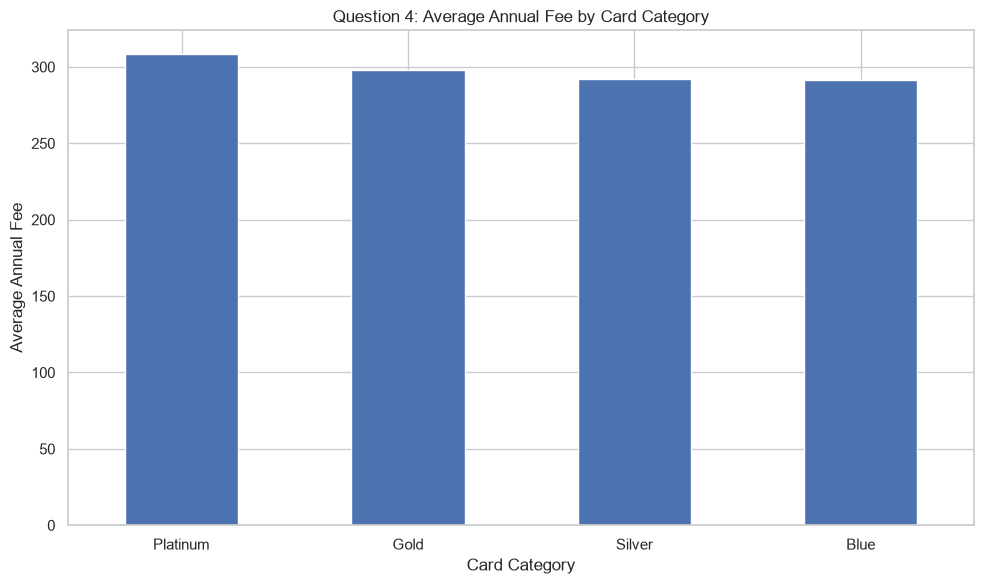

In [22]:
# Calculate the average annual fee for each card category
average_fee = credit_cards.groupby(
    "Card_Category"
)["Annual_Fees"].mean().sort_values(ascending=False)

# Display the results
print(average_fee)

# Create a bar chart
average_fee.plot(kind="bar", rot=0)
plt.title("Question 4: Average Annual Fee by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Average Annual Fee")
plt.tight_layout()
plt.show()

### Question 5: Which expenditure types have the highest total transaction amount?

**Why are we running this code?**

To compare transaction amounts across expenditure types and identify the categories where customers spend the most.

Exp Type
Bills            11166448
Entertainment     7821312
Fuel              7705253
Grocery           7032033
Food              6808437
Travel            4999538
Name: Total_Trans_Amt, dtype: int64


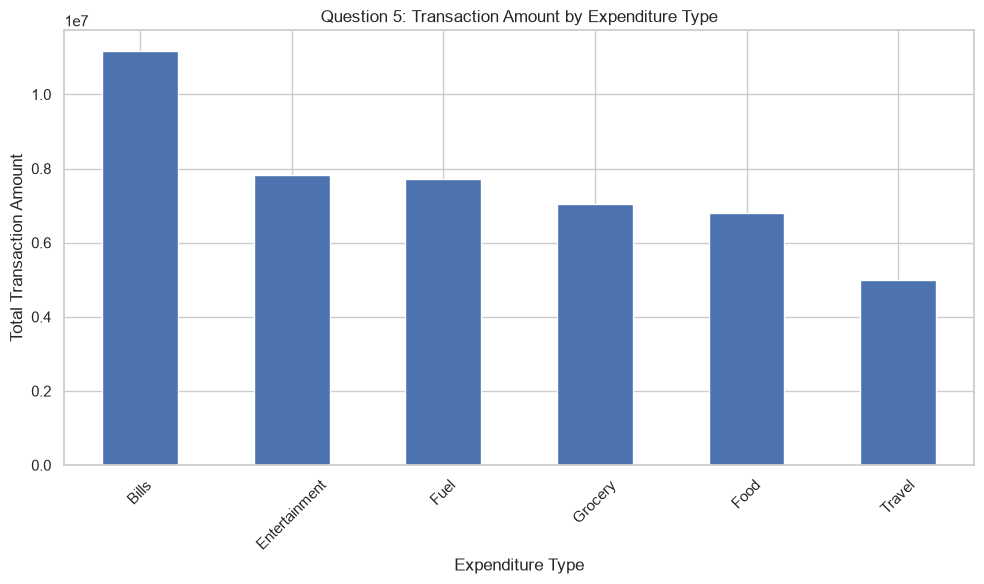

In [23]:
# Calculate total transaction amount for each expenditure type
transaction_by_expense = credit_cards.groupby(
    "Exp Type"
)["Total_Trans_Amt"].sum().sort_values(ascending=False)

# Display the results
print(transaction_by_expense)

# Create a bar chart
transaction_by_expense.plot(kind="bar", rot=45)
plt.title("Question 5: Transaction Amount by Expenditure Type")
plt.xlabel("Expenditure Type")
plt.ylabel("Total Transaction Amount")
plt.tight_layout()
plt.show()

### Question 6: What is the average credit utilization ratio for each credit card category?

**Why are we running this code?**

To compare average credit utilization across card categories and understand how much of their available credit customers use on average.

Card_Category
Blue        0.291737
Platinum    0.151224
Gold        0.124793
Silver      0.083071
Name: Avg_Utilization_Ratio, dtype: float64


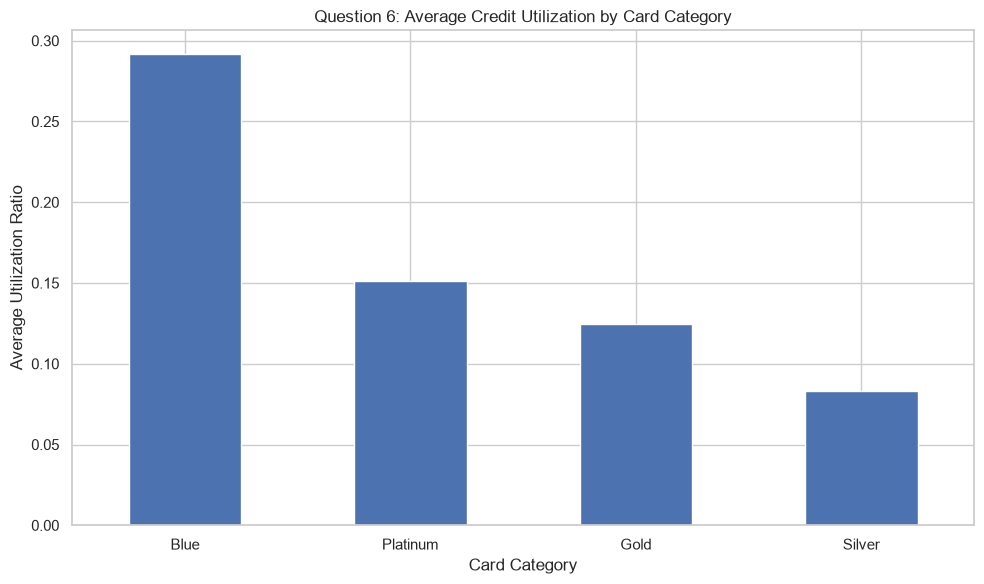

In [24]:
# Calculate average credit utilization for each card category
average_utilization = credit_cards.groupby(
    "Card_Category"
)["Avg_Utilization_Ratio"].mean().sort_values(ascending=False)

# Display the results
print(average_utilization)

# Create a bar chart
average_utilization.plot(kind="bar", rot=0)
plt.title("Question 6: Average Credit Utilization by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Average Utilization Ratio")
plt.tight_layout()
plt.show()

### Question 7: What is the average interest earned for each credit card category?

**Why are we running this code?**

To compare average interest earned across card categories and identify which categories have higher average interest values.

Card_Category
Platinum    2412.373881
Gold        1993.550052
Silver      1266.445270
Blue         704.835104
Name: Interest_Earned, dtype: float64


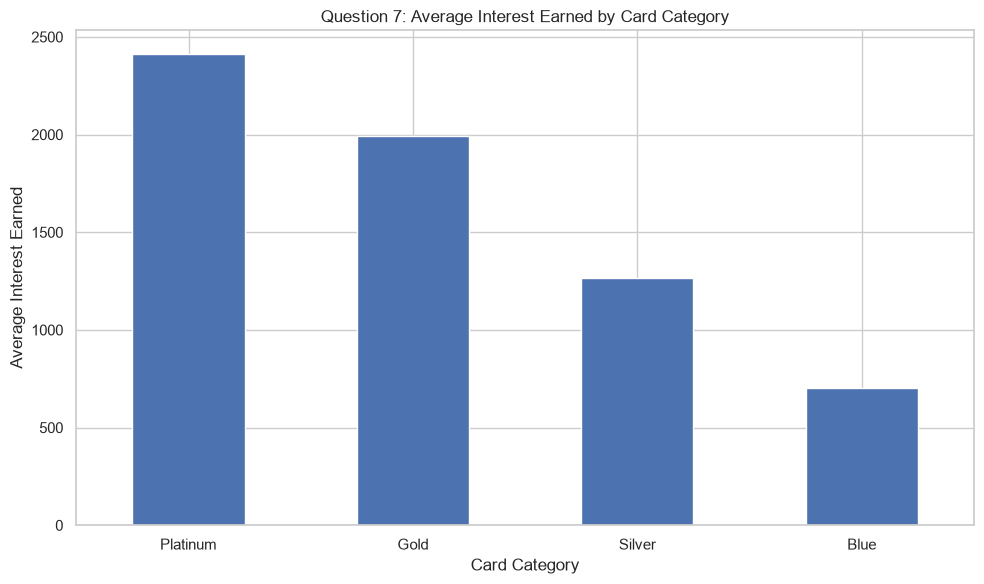

In [25]:
# Calculate average interest earned for each card category
average_interest = credit_cards.groupby(
    "Card_Category"
)["Interest_Earned"].mean().sort_values(ascending=False)

# Display the results
print(average_interest)

# Create a bar chart
average_interest.plot(kind="bar", rot=0)
plt.title("Question 7: Average Interest Earned by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Average Interest Earned")
plt.tight_layout()
plt.show()

### Question 8: What is the total revolving balance for each credit card category?

**Why are we running this code?**

To compare total revolving balances across card categories and understand where the largest recorded outstanding balances are concentrated.

Card_Category
Blue        10823019
Silver        801880
Gold          262882
Platinum       92964
Name: Total_Revolving_Bal, dtype: int64


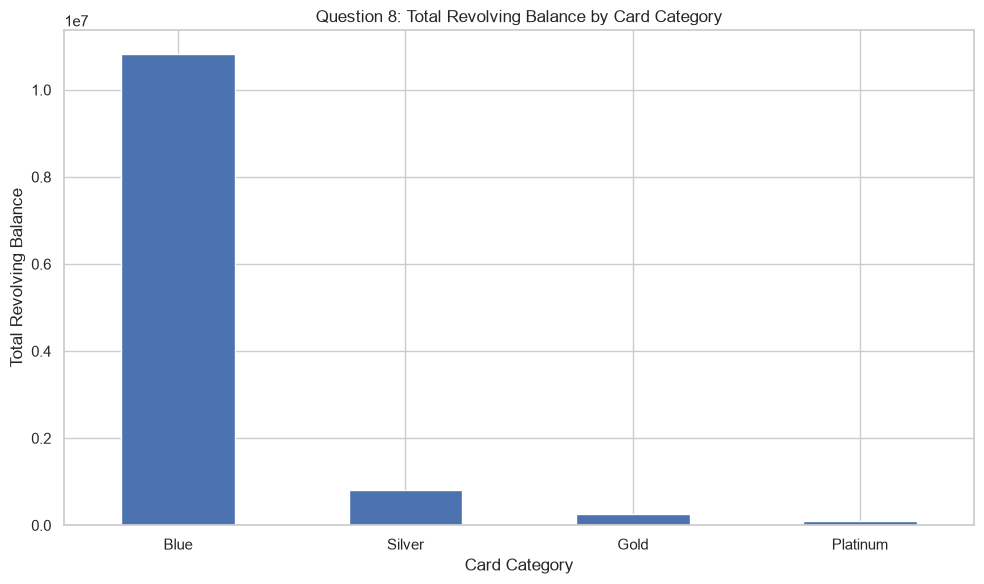

In [26]:
# Calculate total revolving balance for each card category
revolving_by_category = credit_cards.groupby(
    "Card_Category"
)["Total_Revolving_Bal"].sum().sort_values(ascending=False)

# Display the results
print(revolving_by_category)

# Create a bar chart
revolving_by_category.plot(kind="bar", rot=0)
plt.title("Question 8: Total Revolving Balance by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Total Revolving Balance")
plt.tight_layout()
plt.show()

### Question 9: How do transaction amounts differ by card usage method?

**Why are we running this code?**

To compare total transaction amounts by recorded usage method, such as chip or other methods, and identify which method accounts for the highest transaction value.\

Use Chip
Swipe      27894782
Chip       13850621
Online      2776610
Swipe        625178
Chip         315269
Online        70561
Name: Total_Trans_Amt, dtype: int64


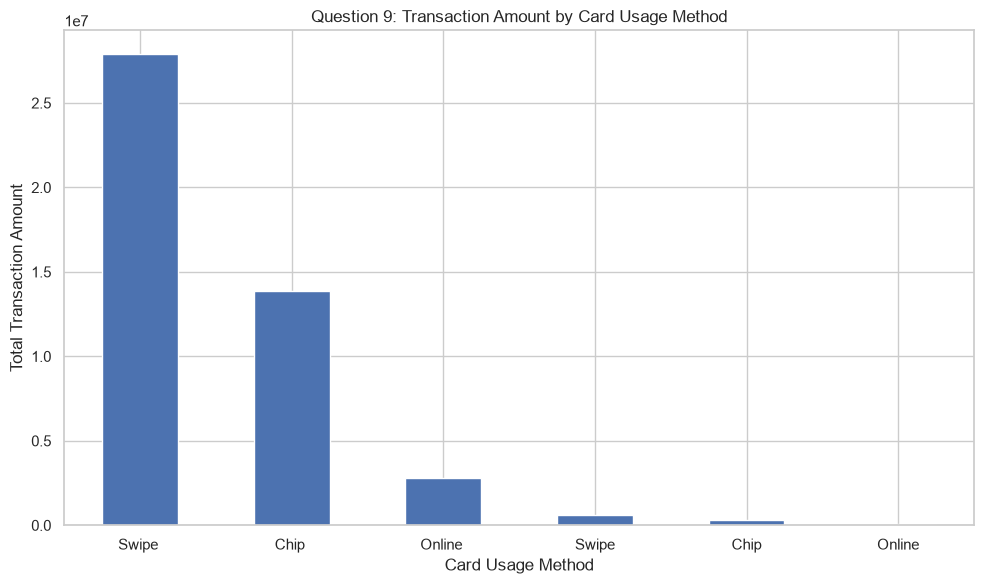

In [27]:
# Calculate total transaction amount by card usage method
transaction_by_method = credit_cards.groupby(
    "Use Chip"
)["Total_Trans_Amt"].sum().sort_values(ascending=False)

# Display the results
print(transaction_by_method)

# Create a bar chart
transaction_by_method.plot(kind="bar", rot=0)
plt.title("Question 9: Transaction Amount by Card Usage Method")
plt.xlabel("Card Usage Method")
plt.ylabel("Total Transaction Amount")
plt.tight_layout()
plt.show()

### Question 10: What percentage of records are marked as delinquent in each credit card category?

**Why are we running this code?**

To compare the recorded delinquency rate across credit card categories. This helps identify categories with a higher proportion of records marked as delinquent.

Card_Category
Gold        6.217617
Silver      6.163328
Blue        6.052856
Platinum    5.970149
Name: Delinquent_Acc, dtype: float64


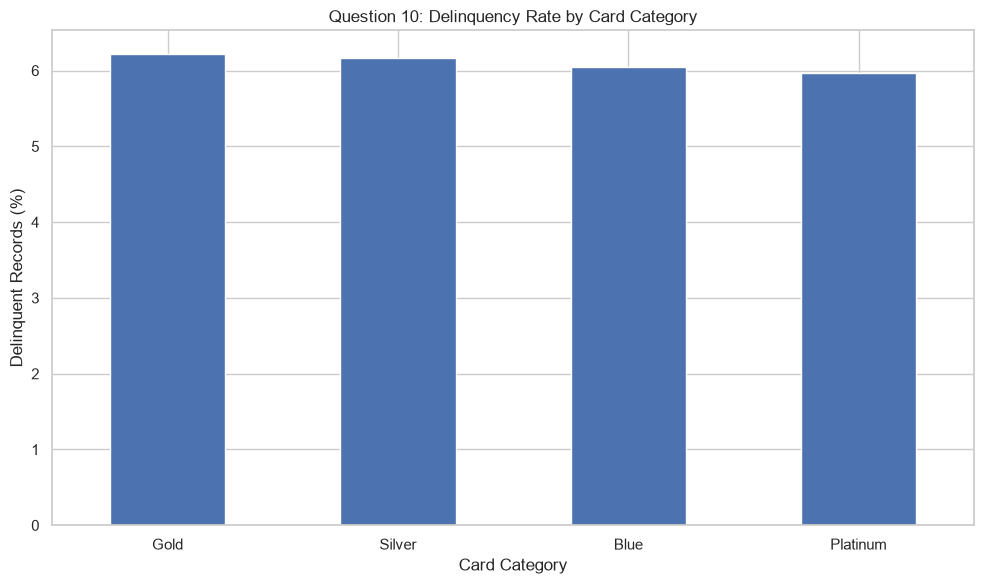

In [28]:
# Calculate the percentage of records marked delinquent in each category
delinquency_rate = credit_cards.groupby("Card_Category")[
    "Delinquent_Acc"
].apply(
    lambda x: (
        x.astype(str).str.strip().str.upper().isin(["1", "YES", "Y", "TRUE"]).mean()
    ) * 100
).sort_values(ascending=False)

# Display the percentages
print(delinquency_rate)

# Create a bar chart
delinquency_rate.plot(kind="bar", rot=0)
plt.title("Question 10: Delinquency Rate by Card Category")
plt.xlabel("Card Category")
plt.ylabel("Delinquent Records (%)")
plt.tight_layout()
plt.show()